<a href="https://colab.research.google.com/github/saichandanss2190/ITA0615-Machine-Learning-192312190-/blob/main/Exp_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Converged at iteration 25


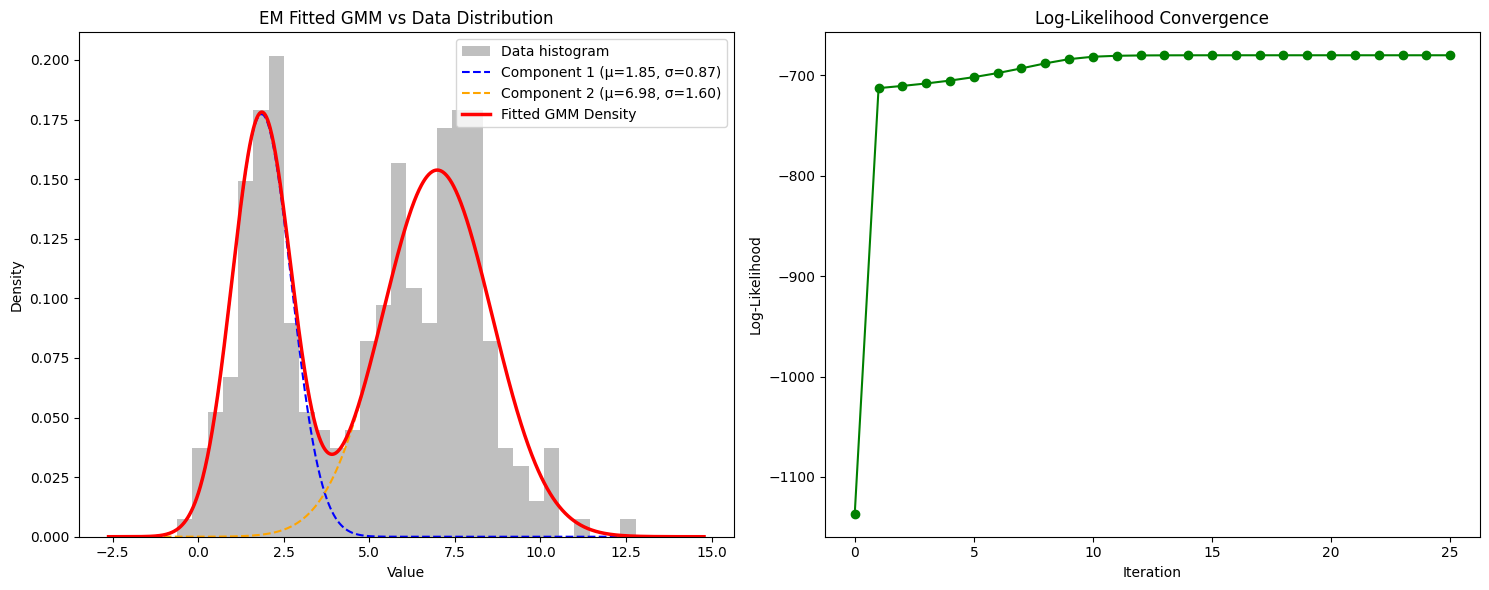

=== Estimated Parameters ===
Component 1: Mean = 1.8513, Std Dev = 0.8667, Weight = 0.3851
Component 2: Mean = 6.9838, Std Dev = 1.5950, Weight = 0.6149


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# 1. Generate Synthetic Data from two Gaussians
np.random.seed(42)
mu1_true, sigma1_true = 2.0, 1.0
mu2_true, sigma2_true = 7.0, 1.5
weight1_true = 0.4
weight2_true = 0.6

n_samples = 300
n_samples1 = int(n_samples * weight1_true)
n_samples2 = n_samples - n_samples1

x1 = np.random.normal(mu1_true, sigma1_true, n_samples1)
x2 = np.random.normal(mu2_true, sigma2_true, n_samples2)
X = np.concatenate([x1, x2])

# 2. EM Algorithm Implementation
def em_gmm(X, K=2, max_iters=100, tol=1e-6):
    # Initialize parameters
    n = len(X)
    # Initial guesses
    mu = np.linspace(min(X), max(X), K)
    sigma = np.ones(K) * np.std(X)
    weights = np.ones(K) / K

    log_likelihoods = []

    for i in range(max_iters):
        # --- Expectation Step (E-step) ---
        # Compute responsibilities (posterior probabilities)
        responsibilities = np.zeros((n, K))
        for k in range(K):
            responsibilities[:, k] = weights[k] * norm.pdf(X, mu[k], sigma[k])

        # Normalize responsibilities
        sum_responsibilities = responsibilities.sum(axis=1, keepdims=True)
        responsibilities /= sum_responsibilities

        # Calculate log-likelihood to check convergence
        log_likelihood = np.sum(np.log(sum_responsibilities))
        log_likelihoods.append(log_likelihood)

        # --- Maximization Step (M-step) ---
        # Update parameters
        N_k = responsibilities.sum(axis=0)

        for k in range(K):
            mu[k] = np.sum(responsibilities[:, k] * X) / N_k[k]
            sigma[k] = np.sqrt(np.sum(responsibilities[:, k] * (X - mu[k])**2) / N_k[k])
            weights[k] = N_k[k] / n

        # Check for convergence
        if i > 0 and abs(log_likelihoods[-1] - log_likelihoods[-2]) < tol:
            print(f'Converged at iteration {i}')
            break

    return mu, sigma, weights, log_likelihoods

# Run EM
mu_est, sigma_est, weights_est, log_lik = em_gmm(X, K=2)

# 3. Presentable Output Visualizations
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Estimated Density vs Actual Histogram
axes[0].hist(X, bins=30, density=True, alpha=0.5, color='gray', label='Data histogram')
x_plot = np.linspace(min(X)-2, max(X)+2, 1000)

# Individual components
component1 = weights_est[0] * norm.pdf(x_plot, mu_est[0], sigma_est[0])
component2 = weights_est[1] * norm.pdf(x_plot, mu_est[1], sigma_est[1])
gmm_mixture = component1 + component2

axes[0].plot(x_plot, component1, '--', color='blue', label=f'Component 1 (μ={mu_est[0]:.2f}, σ={sigma_est[0]:.2f})')
axes[0].plot(x_plot, component2, '--', color='orange', label=f'Component 2 (μ={mu_est[1]:.2f}, σ={sigma_est[1]:.2f})')
axes[0].plot(x_plot, gmm_mixture, '-', color='red', linewidth=2.5, label='Fitted GMM Density')
axes[0].set_title('EM Fitted GMM vs Data Distribution')
axes[0].set_xlabel('Value')
axes[0].set_ylabel('Density')
axes[0].legend()

# Plot 2: Convergence
axes[1].plot(log_lik, marker='o', color='green')
axes[1].set_title('Log-Likelihood Convergence')
axes[1].set_xlabel('Iteration')
axes[1].set_ylabel('Log-Likelihood')

plt.tight_layout()
plt.show()

# Print final parameters
print("=== Estimated Parameters ===")
for k in range(2):
    print(f"Component {k+1}: Mean = {mu_est[k]:.4f}, Std Dev = {sigma_est[k]:.4f}, Weight = {weights_est[k]:.4f}")
